# Customer Segmentation with Clustering

**Family:** End-to-end project | **Dataset:** `telco_churn` | **Task:** clustering

Segment telecom customers on usage and tenure, check stability, and read the segments with churn as an outside check.

## Table of Contents

- 1. Problem statement
- 2. Business or research context
- 3. Dataset documentation
- 4. Research references
- 5. Exploratory analysis
- 6. Preprocessing
- 7. Model selection
- 8. Model training
- 9. Evaluation
- 10. Comparison
- 11. Interpretation
- 12. Limitations
- 13. Final recommendations

## 1. Problem statement

Group customers into segments that a marketing team can act on, using account and service information only.

## 2. Business or research context

Segments let a business tailor offers. A segmentation is useful only if it is stable under resampling and the segments differ in ways people can describe. Churn is **not** used to fit the clusters. It is used afterwards as an external check.

## 3. Dataset documentation

**Telco customer churn**, IBM sample data from the repository `IBM/telco-customer-churn-on-icp4d` (code licence Apache-2.0, dataset terms not stated). 7043 customers, 20 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account (`tenure` in months, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`) and services (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`). Target `Churn` (1 = customer left). `TotalCharges` has blank strings that become missing values. The file is downloaded once and checked against a SHA-256 hash. Limit: one snapshot, no time dimension. Duplicate rows are reported in the EDA but kept, because without an identifier we cannot tell whether they are different customers.

## 4. Research references

Verification status is from the build environment on 2026-11-17. Entries marked *not verified* must be checked before citing.

- Lloyd, S. P. (1982). *Least squares quantization in PCM*. IEEE Transactions on Information Theory 28(2):129-137. https://doi.org/10.1109/TIT.1982.1056489 Verification: Crossref 2026-11-17
- Rousseeuw, P. J. (1987). *Silhouettes: A graphical aid to the interpretation and validation of cluster analysis*. Journal of Computational and Applied Mathematics 20:53-65. https://doi.org/10.1016/0377-0427(87)90125-7 Verification: Crossref 2026-11-17
- Dempster, A. P., Laird, N. M. and Rubin, D. B. (1977). *Maximum Likelihood from Incomplete Data Via the EM Algorithm*. Journal of the Royal Statistical Society B 39(1):1-22. https://doi.org/10.1111/j.2517-6161.1977.tb01600.x Verification: Crossref 2026-11-17

K-means (Lloyd), the silhouette (Rousseeuw) and Gaussian mixtures (Dempster et al.) are compared.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline, build_preprocessor
from ml_lab.evaluation import evaluate_estimator, internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
PROJECT_ID = "customer_segmentation"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("telco_churn")
X, y = bundle.X, bundle.y
print(X.shape)

(7043, 19)


## 5. Exploratory analysis

We use tenure, monthly charges, total charges and the count of add-on services.

In [3]:
services = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
F = pd.DataFrame({"tenure": X["tenure"], "MonthlyCharges": X["MonthlyCharges"], "TotalCharges": X["TotalCharges"].fillna(X["TotalCharges"].median()),
                  "n_addons": X[services].eq("Yes").sum(axis=1)})
display(F.describe().round(1))
print("correlation of tenure and TotalCharges:", round(float(F["tenure"].corr(F["TotalCharges"])), 3))

,tenure,MonthlyCharges,TotalCharges,n_addons
count,7043.0,7043.0,7043.0,7043.0
mean,32.4,64.8,2281.9,2.0
std,24.6,30.1,2265.3,1.8
min,0.0,18.2,18.8,0.0
25%,9.0,35.5,402.2,0.0
50%,29.0,70.4,1397.5,2.0
75%,55.0,89.8,3786.6,3.0
max,72.0,118.8,8684.8,6.0


correlation of tenure and TotalCharges: 0.825


## 6. Preprocessing

Standardise the four features. There is no train and test split because we describe existing customers, but we test stability by resampling.

In [4]:
from sklearn.preprocessing import StandardScaler
Z = StandardScaler().fit_transform(F)
print(Z.shape)

(7043, 4)


## 7. Model selection

Compare k-means and a Gaussian mixture for k from 2 to 8 using silhouette (k-means) and BIC (mixture).

In [5]:
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    gm = GaussianMixture(k, n_init=3, random_state=SEED).fit(Z)
    rows.append({"k": k, "kmeans_silhouette": internal_scores(Z, km.labels_)["Silhouette"], "gmm_BIC": gm.bic(Z)})
sel = pd.DataFrame(rows).set_index("k")
display(sel.round(3))
K = int(sel["kmeans_silhouette"].idxmax()); print("k-means k by silhouette:", K, "| GMM k by BIC:", int(sel["gmm_BIC"].idxmin()))

,kmeans_silhouette,gmm_BIC
k,,
2,0.459,38962.612
3,0.402,8656.554
4,0.395,3081.410
5,0.376,-1817.557
6,0.366,-6644.150
7,0.360,-8966.539
8,0.373,-9633.561


k-means k by silhouette: 2 | GMM k by BIC: 8


## 8. Model training

Fit k-means with the chosen k and test stability on 20 pairs of 80 percent subsamples.

In [6]:
from sklearn.metrics import adjusted_rand_score
model = KMeans(K, n_init=10, random_state=SEED).fit(Z)
labels = model.labels_
rng = np.random.default_rng(SEED); aris = []
for _ in range(20):
    a, b = rng.choice(len(Z), int(0.8 * len(Z)), replace=False), rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    common = np.intersect1d(a, b)
    aris.append(adjusted_rand_score(KMeans(K, n_init=5, random_state=0).fit(Z[a]).predict(Z[common]), KMeans(K, n_init=5, random_state=1).fit(Z[b]).predict(Z[common])))
print("stability ARI over 20 resample pairs: mean", round(float(np.mean(aris)), 3), "std", round(float(np.std(aris, ddof=1)), 3))

stability ARI over 20 resample pairs: mean 0.994 std 0.005


## 9. Evaluation

Internal scores, the stability result and the churn rate of each segment (an outside check, not a fit target).

In [7]:
s = internal_scores(Z, labels)
seg = F.assign(segment=labels, churn=y.values)
profile = seg.groupby("segment").agg(customers=("churn", "size"), churn_rate=("churn", "mean"), tenure=("tenure", "mean"), monthly=("MonthlyCharges", "mean"), addons=("n_addons", "mean")).round(2)
display(profile)
METRICS = {**s, "stability_ARI_mean": float(np.mean(aris)), "stability_ARI_std": float(np.std(aris, ddof=1)), "churn_rate_min_segment": float(profile.churn_rate.min()), "churn_rate_max_segment": float(profile.churn_rate.max())}
CONFIG = {"k": K, "features": list(F.columns), "n_init": 10}
EXTRA = {"profile": profile.reset_index().to_dict("records")}
ALGORITHM = "KMeans"

record = ExperimentRecord(notebook=PROJECT_ID, family="project", algorithm=ALGORITHM, dataset="telco_churn", task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,customers,churn_rate,tenure,monthly,addons
segment,,,,,
0,4486,0.32,19.75,50.88,0.98
1,2557,0.17,54.51,89.12,3.89


saved: /home/claude/open-python/experiments/results/customer_segmentation.json


,metric
clusters,2.0000
noise_fraction,0.0000
Silhouette,0.4587
Davies_Bouldin,0.8422
Calinski_Harabasz,8066.8613
stability_ARI_mean,0.9942
stability_ARI_std,0.0049
churn_rate_min_segment,0.1700
churn_rate_max_segment,0.3200


## 10. Comparison

Compare k-means with a Gaussian mixture at the same k, using agreement (ARI) and silhouette.

In [8]:
gm = GaussianMixture(K, n_init=3, random_state=SEED).fit(Z)
print("agreement k-means vs GMM (ARI):", round(adjusted_rand_score(labels, gm.predict(Z)), 3), "| GMM silhouette:", round(internal_scores(Z, gm.predict(Z))["Silhouette"], 3), "| k-means silhouette:", round(s["Silhouette"], 3))

agreement k-means vs GMM (ARI): 0.142 | GMM silhouette: 0.327 | k-means silhouette: 0.459


## 11. Interpretation

Plot the segments in the plane of tenure and monthly charges and read the profile table.

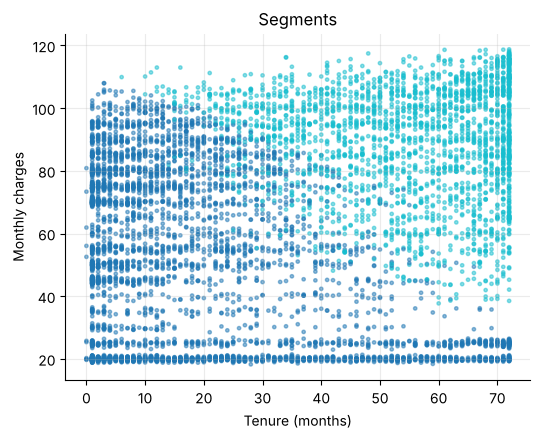

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sc = ax.scatter(F["tenure"], F["MonthlyCharges"], c=labels, cmap="tab10", s=6, alpha=0.5)
ax.set_xlabel("Tenure (months)"); ax.set_ylabel("Monthly charges"); ax.set_title("Segments"); save_figure(fig, PROJECT_ID, "segments"); plt.show()

## 12. Limitations

Four numeric features only, so segments mostly separate by tenure and price. Segment churn rates are an association, not a causal effect. Silhouette values are low for this kind of data, which means segments overlap.

## 13. Final recommendations

Use the segments as a descriptive tool. Check stability on new months of data, add behavioural features (usage, support calls) when available, and test an offer per segment with a control group.